# 02 · Demand Analysis
*What moves demand: trend, seasonality, events, SNAP, and price.*

> ⚠️ **Synthetic data.** These notebooks run on the generated M5-shaped sample so every
> cell is reproducible out of the box. The *mechanics* are real; the *numbers are not a
> business finding*. Set `data_source.mode: real` in `config.yaml`, drop the Kaggle M5
> files into `data/raw/`, run `make all`, and re-run — every cell applies unchanged.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')  # run from project root whether launched here or above
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
con = duckdb.connect('data/processed/rci.duckdb', read_only=True)
EXT = 'dashboard/extracts'
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 20)

## Trend — units and value, monthly

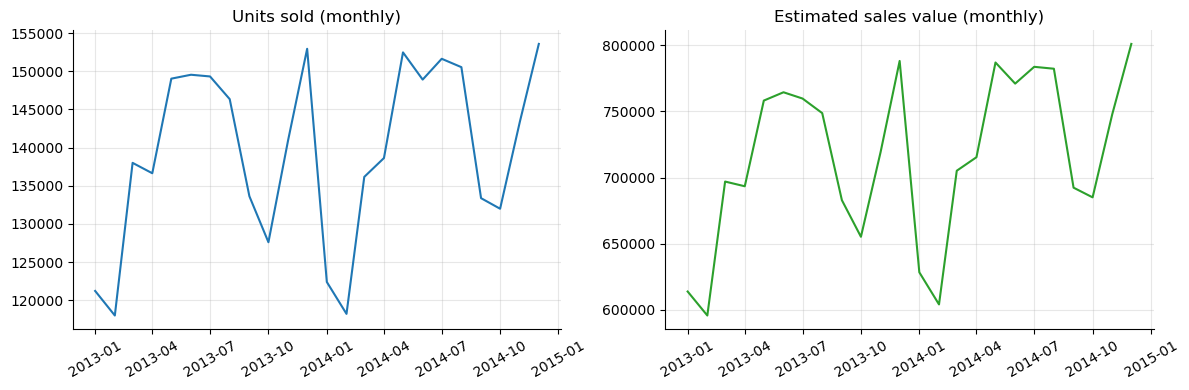

In [2]:
m = con.execute('''SELECT date_trunc('month', date_key) m, SUM(units) units,
                          SUM(sales_value) val FROM mart_daily GROUP BY 1 ORDER BY 1''').df()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(m.m, m.units); ax[0].set_title('Units sold (monthly)')
ax[1].plot(m.m, m.val, color='tab:green'); ax[1].set_title('Estimated sales value (monthly)')
for a in ax: a.set_xlabel(''); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

## Seasonality — day of week & month

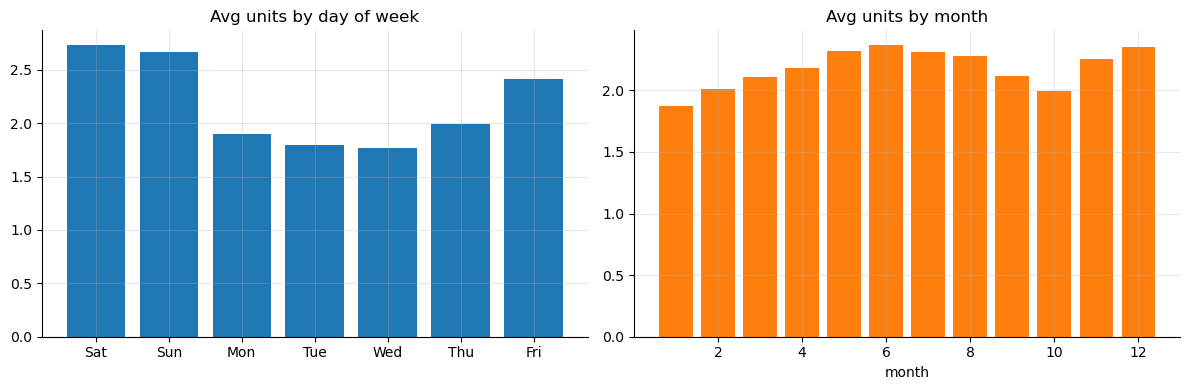

In [3]:
dow = con.execute('''SELECT wday, AVG(units) u FROM mart_daily GROUP BY 1 ORDER BY 1''').df()
labels = ['Sat','Sun','Mon','Tue','Wed','Thu','Fri']
mon = con.execute('''SELECT month, AVG(units) u FROM mart_daily GROUP BY 1 ORDER BY 1''').df()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(labels, dow.u); ax[0].set_title('Avg units by day of week')
ax[1].bar(mon.month, mon.u, color='tab:orange'); ax[1].set_title('Avg units by month'); ax[1].set_xlabel('month')
plt.tight_layout(); plt.show()

## Event effects
Average daily units on event days vs. ordinary days, by category — the holiday lift.

In [4]:
ev = con.execute('''SELECT cat_id,
     AVG(CASE WHEN event_name IS NOT NULL THEN units END) event_day,
     AVG(CASE WHEN event_name IS NULL THEN units END) normal_day
   FROM mart_daily GROUP BY 1''').df()
ev['lift_%'] = (100*(ev.event_day/ev.normal_day - 1)).round(1)
display(ev.round(2))

,cat_id,event_day,normal_day,lift_%
0,HOUSEHOLD,1.19,1.29,-7.4
1,HOBBIES,0.75,0.71,5.0
2,FOODS,4.39,3.74,17.3


## SNAP effect on FOODS
SNAP benefits are food-focused, so we test the lift on FOODS specifically.

In [5]:
snap = con.execute('''SELECT snap_active, AVG(units) u FROM mart_daily
   WHERE cat_id = 'FOODS' GROUP BY 1 ORDER BY 1''').df()
lift = 100*(snap.u.iloc[1]/snap.u.iloc[0] - 1)
print(f'FOODS avg units — non-SNAP {snap.u.iloc[0]:.2f}  vs  SNAP {snap.u.iloc[1]:.2f}  (+{lift:.1f}%)')

FOODS avg units — non-SNAP 3.49  vs  SNAP 4.30  (+23.1%)


## Price–demand association
Each point is a store×category segment: its price change vs its demand change over the
comparison window. A downward tilt is consistent with a demand curve — but this is
**association, not proof of causation** (promotions, events, stock-outs are uncontrolled).

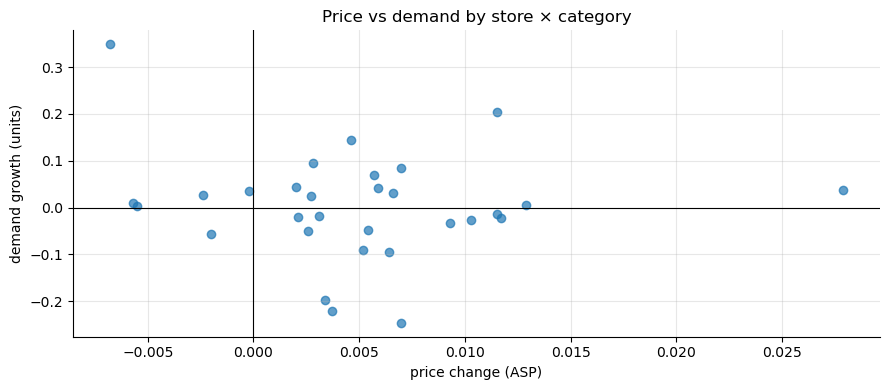

In [6]:
pd_ = pd.read_csv(f'{EXT}/price_demand.csv').dropna(subset=['price_change','demand_growth'])
plt.scatter(pd_.price_change, pd_.demand_growth, alpha=.7)
plt.axhline(0, lw=.8, color='k'); plt.axvline(0, lw=.8, color='k')
plt.xlabel('price change (ASP)'); plt.ylabel('demand growth (units)')
plt.title('Price vs demand by store × category'); plt.tight_layout(); plt.show()

### Takeaways
- Clear weekly seasonality (weekend peak) and a Q4 holiday ramp.
- Events and SNAP both lift demand where expected (FOODS strongest) — usable planning signals.
- The price–demand tilt is negative on average, consistent with elastic demand; report as association.